#### Analysis of Employee Success Rates


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [5]:
#loading the dataset
df = pd.read_csv('datasets/hr2.csv')
df.head()

,employee_id,department,region,education,gender,recruitment_channel,no_of_trainings,age,previous_year_rating,length_of_service,KPIs_met >80%,awards_won?,avg_training_score,is_promoted
0,65438,Sales & Marketing,region_7,Master's & above,f,sourcing,1,35,5.0,8,1,0,49,0
1,65141,Operations,region_22,Bachelor's,m,other,1,30,5.0,4,0,0,60,0
2,7513,Sales & Marketing,region_19,Bachelor's,m,sourcing,1,34,3.0,7,0,0,50,0
3,2542,Sales & Marketing,region_23,Bachelor's,m,other,2,39,1.0,10,0,0,50,0
4,48945,Technology,region_26,Bachelor's,m,other,1,45,3.0,2,0,0,73,0


In [6]:
df.tail()

,employee_id,department,region,education,gender,recruitment_channel,no_of_trainings,age,previous_year_rating,length_of_service,KPIs_met >80%,awards_won?,avg_training_score,is_promoted
54803,3030,Technology,region_14,Bachelor's,m,sourcing,1,48,3.0,17,0,0,78,0
54804,74592,Operations,region_27,Master's & above,f,other,1,37,2.0,6,0,0,56,0
54805,13918,Analytics,region_1,Bachelor's,m,other,1,27,5.0,3,1,0,79,0
54806,13614,Sales & Marketing,region_9,NaN,m,sourcing,1,29,1.0,2,0,0,45,0
54807,51526,HR,region_22,Bachelor's,m,other,1,27,1.0,5,0,0,49,0


In [7]:
#cleaning the dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 54808 entries, 0 to 54807
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   employee_id           54808 non-null  int64  
 1   department            54808 non-null  str    
 2   region                54808 non-null  str    
 3   education             52399 non-null  str    
 4   gender                54808 non-null  str    
 5   recruitment_channel   54808 non-null  str    
 6   no_of_trainings       54808 non-null  int64  
 7   age                   54808 non-null  int64  
 8   previous_year_rating  50684 non-null  float64
 9   length_of_service     54808 non-null  int64  
 10  KPIs_met >80%         54808 non-null  int64  
 11  awards_won?           54808 non-null  int64  
 12  avg_training_score    54808 non-null  int64  
 13  is_promoted           54808 non-null  int64  
dtypes: float64(1), int64(8), str(5)
memory usage: 5.9 MB


#### 2. Cleaning the data

In [8]:
print("Missing values per column:\n", df.isnull().sum())

Missing values per column:
 employee_id                0
department                 0
region                     0
education               2409
gender                     0
recruitment_channel        0
no_of_trainings            0
age                        0
previous_year_rating    4124
length_of_service          0
KPIs_met >80%              0
awards_won?                0
avg_training_score         0
is_promoted                0
dtype: int64


In [9]:
df['education'] = df['education'].fillna(df['education'].mode()[0])
df['previous_year_rating'] = df['previous_year_rating'].fillna(3.0)

In [10]:
categorical_cols = ['department', 'region', 'education', 'gender', 'recruitment_channel']
for col in categorical_cols:
    df[col] = df[col].astype('category')

In [11]:
df.isnull().sum()

employee_id             0
department              0
region                  0
education               0
gender                  0
recruitment_channel     0
no_of_trainings         0
age                     0
previous_year_rating    0
length_of_service       0
KPIs_met >80%           0
awards_won?             0
avg_training_score      0
is_promoted             0
dtype: int64

#### 3. Exploratory Data analysis


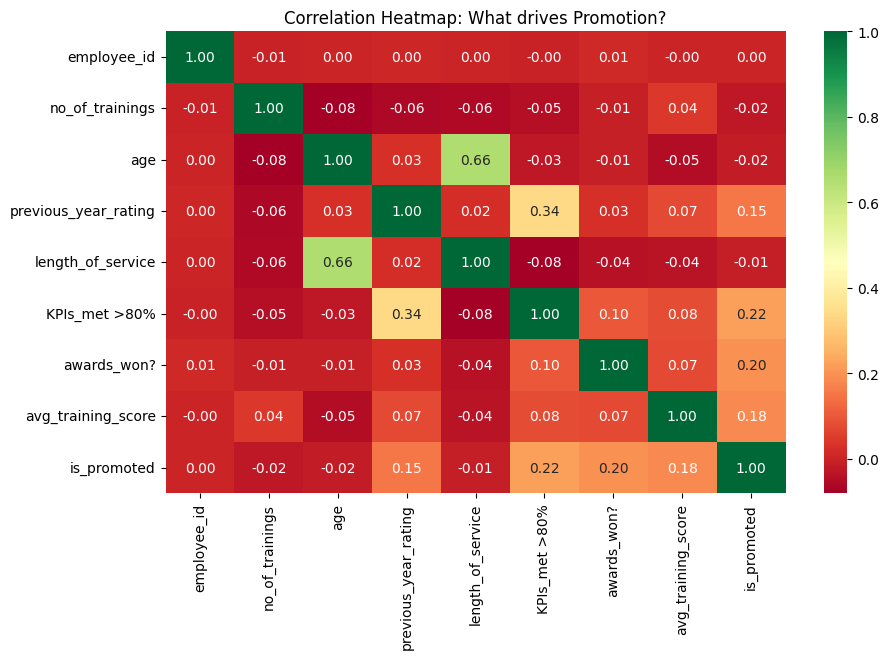

In [14]:

plt.figure(figsize=(10, 6))
correlation_matrix = df.select_dtypes(include=[np.number]).corr()

sns.heatmap(correlation_matrix, annot=True, cmap='RdYlGn', fmt='.2f')
plt.title('Correlation Heatmap: What drives Promotion?')
plt.show()

In [17]:
n_promoted     = df["is_promoted"].sum()
n_not_promoted = len(df) - n_promoted
ratio          = n_not_promoted / n_promoted
print("Promotion balance:")
print(f"  Promoted     : {n_promoted:,}  ({n_promoted/len(df)*100:.1f}%)")
print(f"  Not promoted : {n_not_promoted:,}  ({n_not_promoted/len(df)*100:.1f}%)")
print(f"  Imbalance    : {ratio:.1f}× more non-promoted than promoted")

Promotion balance:
  Promoted     : 4,668  (8.5%)
  Not promoted : 50,140  (91.5%)
  Imbalance    : 10.7× more non-promoted than promoted


C:\Users\alvin\AppData\Local\Temp\ipykernel_5104\492316086.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='is_promoted', y='avg_training_score', data=df, ax=axes[0], palette='viridis')
C:\Users\alvin\AppData\Local\Temp\ipykernel_5104\492316086.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='KPIs_met >80%', y='is_promoted', data=df, ax=axes[1], palette='magma')


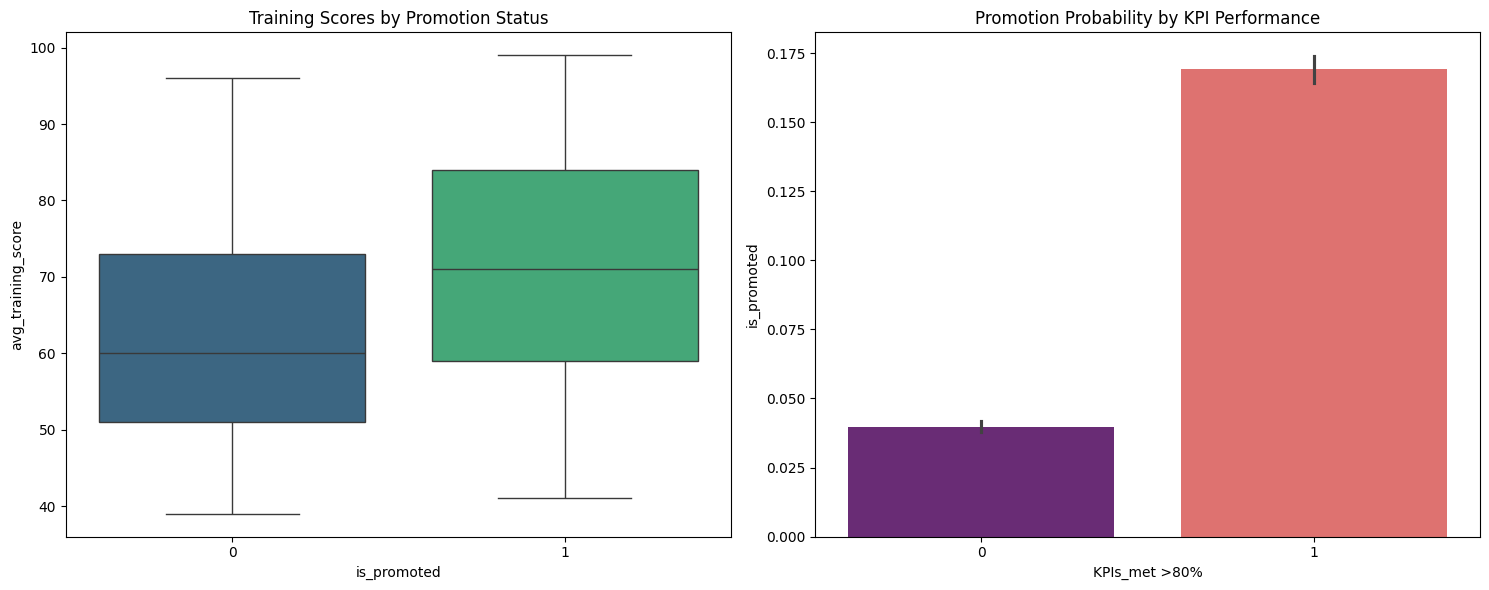

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Training Score vs Promotion
sns.boxplot(x='is_promoted', y='avg_training_score', data=df, ax=axes[0], palette='viridis')
axes[0].set_title('Training Scores by Promotion Status')

# KPI impact on Promotion
sns.barplot(x='KPIs_met >80%', y='is_promoted', data=df, ax=axes[1], palette='magma')
axes[1].set_title('Promotion Probability by KPI Performance')

plt.tight_layout()
plt.show()

In [19]:
numeric_cols = [
    "no_of_trainings", "age", "previous_year_rating",
    "length_of_service", "KPIs_met >80%", "awards_won?", "avg_training_score",
]
 
corr_vals = (
    df[numeric_cols + ["is_promoted"]]
    .corr()["is_promoted"]
    .drop("is_promoted")
    .sort_values()
)


C:\Users\alvin\AppData\Local\Temp\ipykernel_5104\2180411975.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


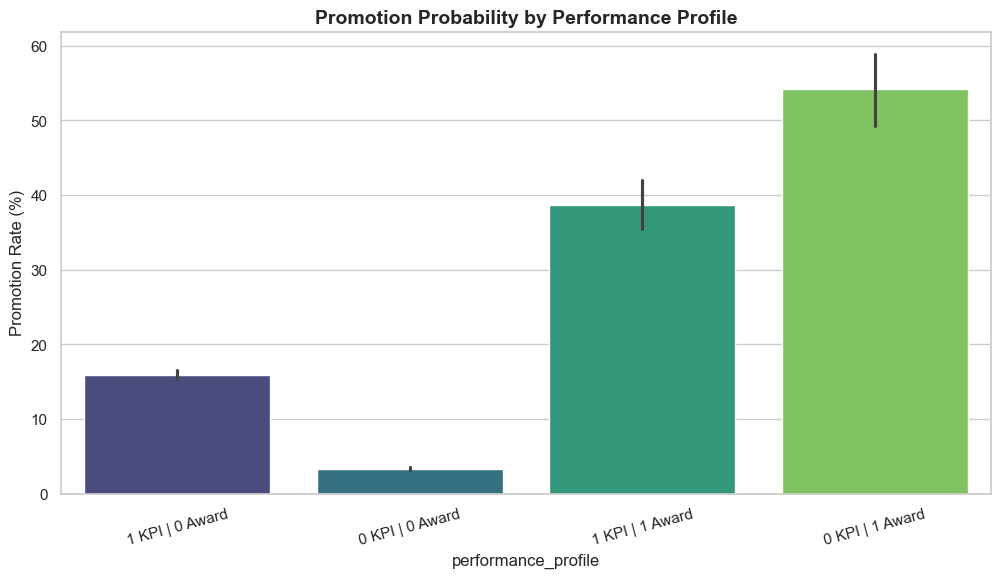

In [30]:
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titleweight'] = 'bold'
# Create a temporary column for easier visualization
df['performance_profile'] = df['KPIs_met >80%'].astype(str) + " KPI | " + df['awards_won?'].astype(str) + " Award"

fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(
    data=df, 
    x='performance_profile', 
    y='is_promoted', 
    estimator=lambda x: sum(x) / len(x) * 100, 
    palette="viridis",
    ax=ax
)

ax.set_title("Promotion Probability by Performance Profile")
ax.set_ylabel("Promotion Rate (%)")
plt.xticks(rotation=15)
plt.show()

In [31]:
#feature engineering: creating a new feature that combines KPIs and awards
df['performance_profile'] = df['KPIs_met >80%'].astype(str) + " KPI | " + df['awards_won?'].astype(str) + " Award"
performance_corr = df.groupby('performance_profile')['is_promoted'].mean().sort_values()


In [32]:
df

,employee_id,department,region,education,gender,recruitment_channel,no_of_trainings,age,previous_year_rating,length_of_service,KPIs_met >80%,awards_won?,avg_training_score,is_promoted,performance_profile
0,65438,Sales & Marketing,region_7,Master's & above,f,sourcing,1,35,5.0,8,1,0,49,0,1 KPI | 0 Award
1,65141,Operations,region_22,Bachelor's,m,other,1,30,5.0,4,0,0,60,0,0 KPI | 0 Award
2,7513,Sales & Marketing,region_19,Bachelor's,m,sourcing,1,34,3.0,7,0,0,50,0,0 KPI | 0 Award
3,2542,Sales & Marketing,region_23,Bachelor's,m,other,2,39,1.0,10,0,0,50,0,0 KPI | 0 Award
4,48945,Technology,region_26,Bachelor's,m,other,1,45,3.0,2,0,0,73,0,0 KPI | 0 Award
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
54803,3030,Technology,region_14,Bachelor's,m,sourcing,1,48,3.0,17,0,0,78,0,0 KPI | 0 Award
54804,74592,Operations,region_27,Master's & above,f,other,1,37,2.0,6,0,0,56,0,0 KPI | 0 Award
54805,13918,Analytics,region_1,Bachelor's,m,other,1,27,5.0,3,1,0,79,0,1 KPI | 0 Award
54806,13614,Sales & Marketing,region_9,Bachelor's,m,sourcing,1,29,1.0,2,0,0,45,0,0 KPI | 0 Award


In [34]:
# ranking departments by promotion rate
department_promotion = df.groupby('department')['is_promoted'].mean().sort_values(ascending=False)
display(department_promotion)

department
Technology           0.107593
Procurement          0.096386
Analytics            0.095665
Operations           0.090148
Finance              0.081230
Sales & Marketing    0.072031
R&D                  0.069069
HR                   0.056245
Legal                0.051011
Name: is_promoted, dtype: float64

In [ ]:
# ranking regions by promotion rate
region_promotion = df.groupby('region')['is_promoted'].mean().sort_values(ascending=False)
display(region_promotion)
sorted_region_promotion = region_promotion.sort_values(ascending=False)
sorted_region_promotion


region
region_4     0.144451
region_17    0.136935
region_25    0.125763
region_28    0.116844
region_23    0.116596
region_22    0.114188
region_3     0.106936
region_7     0.106546
region_1     0.095082
region_30    0.089802
region_13    0.086858
region_8     0.080916
region_2     0.080126
region_15    0.079060
region_27    0.078963
region_10    0.078704
region_14    0.074970
region_16    0.069625
region_12    0.066000
region_26    0.063274
region_19    0.060641
region_20    0.057647
region_31    0.056848
region_11    0.056274
region_6     0.046377
region_5     0.045692
region_21    0.043796
region_29    0.043260
region_32    0.042328
region_33    0.037175
region_24    0.035433
region_18    0.032258
region_34    0.027397
region_9     0.019048
Name: is_promoted, dtype: float64

region
region_4     0.144451
region_17    0.136935
region_25    0.125763
region_28    0.116844
region_23    0.116596
region_22    0.114188
region_3     0.106936
region_7     0.106546
region_1     0.095082
region_30    0.089802
region_13    0.086858
region_8     0.080916
region_2     0.080126
region_15    0.079060
region_27    0.078963
region_10    0.078704
region_14    0.074970
region_16    0.069625
region_12    0.066000
region_26    0.063274
region_19    0.060641
region_20    0.057647
region_31    0.056848
region_11    0.056274
region_6     0.046377
region_5     0.045692
region_21    0.043796
region_29    0.043260
region_32    0.042328
region_33    0.037175
region_24    0.035433
region_18    0.032258
region_34    0.027397
region_9     0.019048
Name: is_promoted, dtype: float64

In [41]:
promotion_counts = df.groupby(['department', 'region', 'is_promoted']).size().unstack(fill_value=0)

# Rename columns for clarity
promotion_counts.columns = ['Not Promoted', 'Promoted']

# Add a 'Total' column for sorting purposes
promotion_counts['Total'] = promotion_counts['Not Promoted'] + promotion_counts['Promoted']

# Sort by number of Promoted individuals in descending order
# You can change 'Promoted' to 'Total' or 'Not Promoted' depending on your priority
sorted_promotions = promotion_counts.sort_values(by='Promoted', ascending=False)

# Reset index to make it a flat table
sorted_promotions = sorted_promotions.reset_index()

# Display the top results
sorted_promotions

,department,region,Not Promoted,Promoted,Total
0,Sales & Marketing,region_2,3049,295,3344
1,Operations,region_22,1341,205,1546
2,Procurement,region_2,1844,202,2046
3,Analytics,region_22,932,182,1114
4,Operations,region_2,1954,179,2133
...,...,...,...,...,...
287,Finance,region_14,23,0,23
288,Finance,region_9,9,0,9
289,Finance,region_10,13,0,13
290,Finance,region_12,10,0,10


--- Promotion Counts by Department ---
                   Not Promoted  Promoted  Total  Promotion %
department                                                   
Sales & Marketing         15627      1213  16840         7.20
Operations                10325      1023  11348         9.01
Technology                 6370       768   7138        10.76
Procurement                6450       688   7138         9.64
Analytics                  4840       512   5352         9.57
Finance                    2330       206   2536         8.12
HR                         2282       136   2418         5.62
R&D                         930        69    999         6.91
Legal                       986        53   1039         5.10


C:\Users\alvin\AppData\Local\Temp\ipykernel_5104\3237381235.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=dept_promo_sorted.index, y='Promoted', data=dept_promo_sorted, palette='viridis')


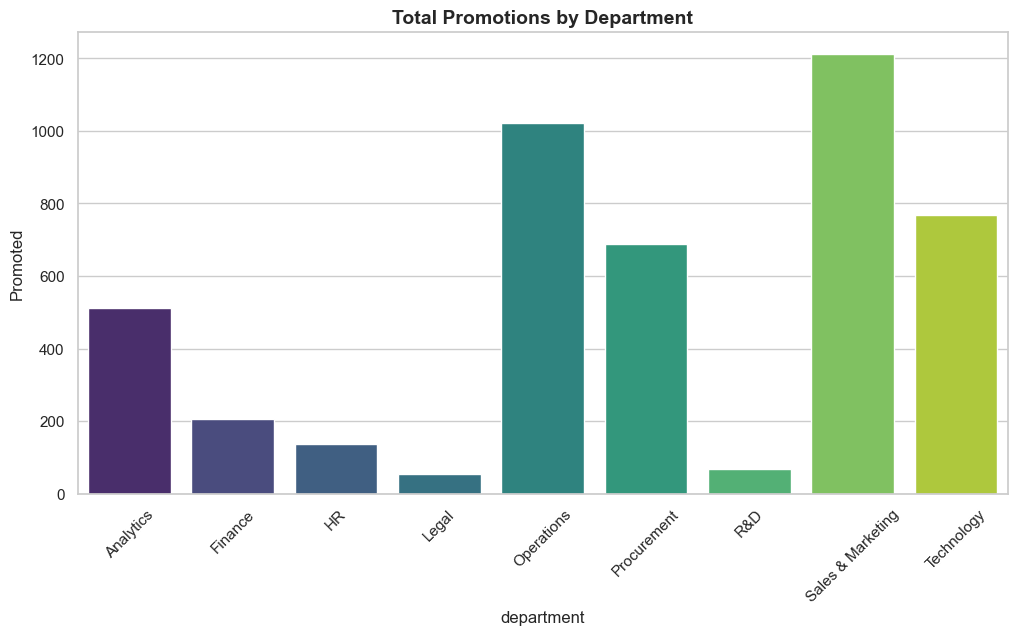

In [91]:
dept_promo = df.groupby(['department', 'is_promoted']).size().unstack(fill_value=0)
dept_promo.columns = ['Not Promoted', 'Promoted']
dept_promo['Total'] = dept_promo['Not Promoted'] + dept_promo['Promoted']
dept_promo['Promotion %'] = (dept_promo['Promoted'] / dept_promo['Total'] * 100).round(2)

# Sort by Promoted count descending
dept_promo_sorted = dept_promo.sort_values(by='Promoted', ascending=False)

print("--- Promotion Counts by Department ---")
print(dept_promo_sorted)

# Visualizing with Seaborn
plt.figure(figsize=(12, 6))
sns.barplot(x=dept_promo_sorted.index, y='Promoted', data=dept_promo_sorted, palette='viridis')
plt.title('Total Promotions by Department')
plt.xticks(rotation=45)
# plt.legend(title='Promotion Status')

plt.show()

--- Promotion Counts by Region (Top 10) ---
           Not Promoted  Promoted  Total  Promotion %
region                                               
region_2          11354       989  12343         8.01
region_22          5694       734   6428        11.42
region_7           4327       516   4843        10.65
region_4           1457       246   1703        14.45
region_13          2418       230   2648         8.69
region_15          2586       222   2808         7.91
region_28          1164       154   1318        11.68
region_26          2117       143   2260         6.33
region_23          1038       137   1175        11.66
region_27          1528       131   1659         7.90


C:\Users\alvin\AppData\Local\Temp\ipykernel_5104\1511222574.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=region_promo_sorted.index[:10], y='Promoted', data=region_promo_sorted.head(10), palette='magma')


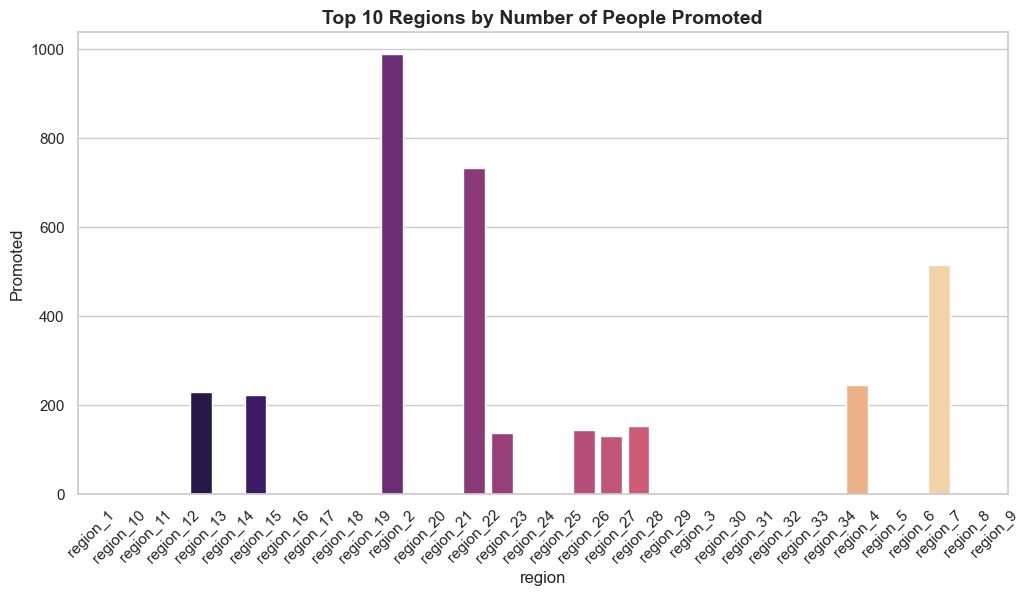

In [ ]:

# Grouping by Region
region_promo = df.groupby(['region', 'is_promoted']).size().unstack(fill_value=0)
region_promo.columns = ['Not Promoted', 'Promoted']
region_promo['Total'] = region_promo['Not Promoted'] + region_promo['Promoted']
region_promo['Promotion %'] = (region_promo['Promoted'] / region_promo['Total'] * 100).round(2)

# Sort by Promoted count descending to see high-performing regions first
region_promo_sorted = region_promo.sort_values(by='Promoted', ascending=False)

print("--- Promotion Counts by Region (Top 10) ---")
print(region_promo_sorted.head(10))

# Visualizing Top 10 Regions with Seaborn
plt.figure(figsize=(12, 6))
sns.barplot(x=region_promo_sorted.index[:10], y='Promoted', data=region_promo_sorted.head(10), palette='magma')
plt.title('Top 10 Regions by Number of People Promoted')
plt.xticks(rotation=45)
plt.show()

In [ ]:
#promotion rates by avg_training_score
training_promo = df.groupby('avg_training_score')['is_promoted'].mean().sort_values(ascending=False)
print("--- Promotion Rates by Average Training Score ---")
training_promo


--- Promotion Rates by Average Training Score ---


avg_training_score
95    1.000000
97    1.000000
98    1.000000
99    1.000000
96    0.979167
        ...   
42    0.032258
46    0.031690
44    0.029851
40    0.000000
39    0.000000
Name: is_promoted, Length: 61, dtype: float64

C:\Users\alvin\AppData\Local\Temp\ipykernel_5104\2335803579.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=training_promo.index, y=training_promo.values, palette='coolwarm')


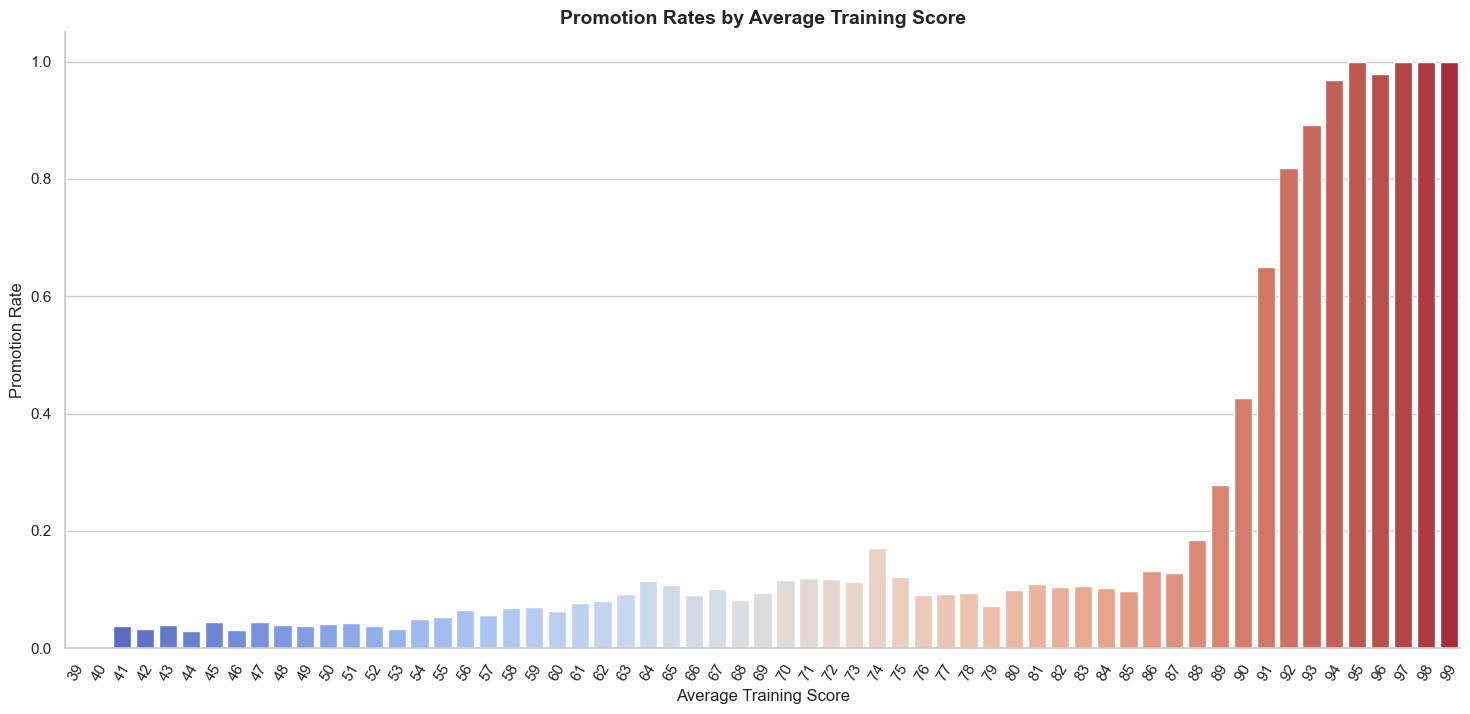

In [90]:
# visual of promotion rates by avg_training_score
plt.figure(figsize=(18, 8))
sns.barplot(x=training_promo.index, y=training_promo.values, palette='coolwarm')
plt.title('Promotion Rates by Average Training Score')
plt.xlabel('Average Training Score')
plt.ylabel('Promotion Rate')
plt.xticks(rotation=60)
# plt.legend( title='Promotion Rate', loc='upper left', labels=[f"{rate:.1%}" for rate in training_promo.values])
sns.despine()
# plt.tight_layout()
plt.show()



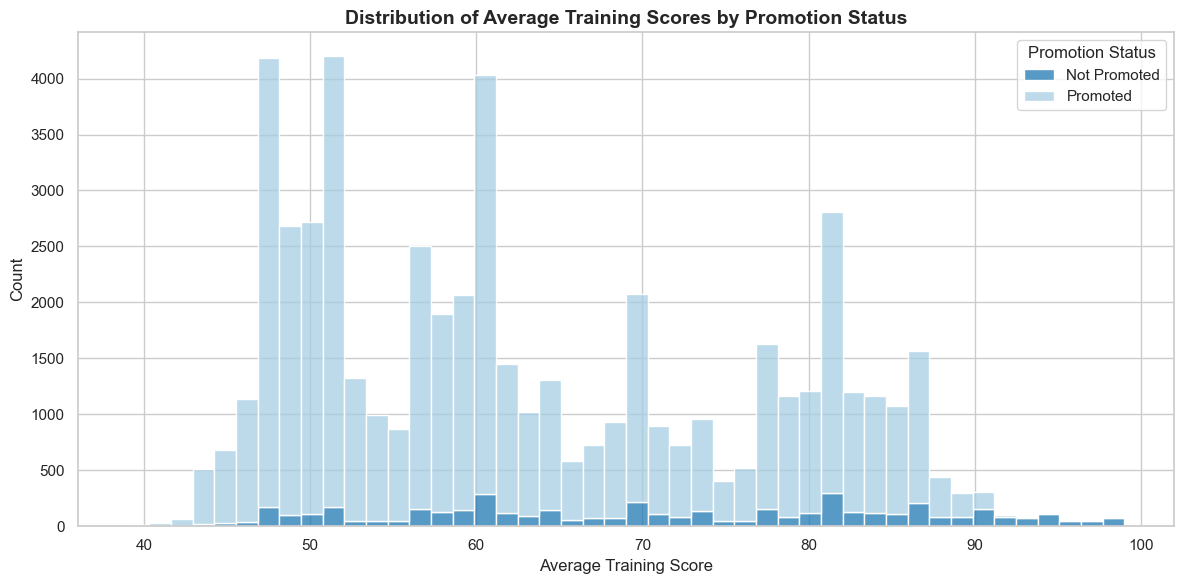

In [66]:
# histogram of avg_training_score by promotion status
plt.figure(figsize=(12, 6))
sns.histplot(data=df, x='avg_training_score', hue='is_promoted', multiple='stack', palette='Paired')
plt.title('Distribution of Average Training Scores by Promotion Status')
plt.xlabel('Average Training Score')
plt.ylabel('Count')
sns.despine
plt.legend(title='Promotion Status' , labels=['Not Promoted', 'Promoted'])
plt.tight_layout()
plt.show()

             

In [67]:
# high potential employees: those with high training scores, KPIs, and awards not yet promoted
high_potential = df[
    (df["is_promoted"] == 0) &
    (df["KPIs_met >80%"] == 1) &
    (df["avg_training_score"] >= 60)
].copy()


In [69]:
print(f"High-potential employees (not yet promoted): {len(high_potential):,}")
print(f"  % of total workforce : {len(high_potential)/len(df)*100:.1f}%")
print()
print("Profile:")
print(f"  Avg age              : {high_potential['age'].mean():.1f}")
print(f"  Avg length of service: {high_potential['length_of_service'].mean():.1f} yrs")
rating_mean = high_potential["previous_year_rating"].mean()
print(f"  Avg previous rating  : {rating_mean:.2f}")
awards_pct  = high_potential["awards_won?"].mean() * 100
print(f"  Awards won           : {awards_pct:.1f}%")
print()


High-potential employees (not yet promoted): 9,015
  % of total workforce : 16.4%

Profile:
  Avg age              : 34.5
  Avg length of service: 5.4 yrs
  Avg previous rating  : 3.89
  Awards won           : 3.2%



In [71]:
print("By department:")
hp_dept = (
    high_potential.groupby("department")
    .size()
    .sort_values(ascending=False)
    .rename("hp_count")
)
print(hp_dept.to_string())
 

By department:
department
Procurement    2195
Operations     2119
Technology     1923
Analytics      1808
Finance         449
R&D             366
Legal           155


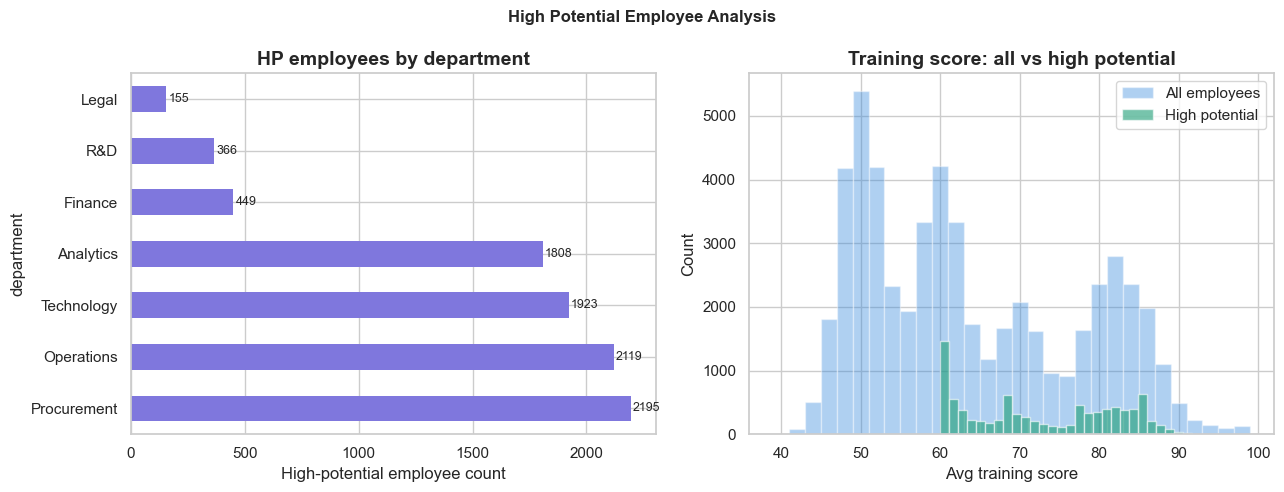

In [73]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
 
# Bar: HP count by dept
hp_dept.plot.barh(ax=axes[0], color=C_PURPLE, edgecolor="none")
axes[0].set_xlabel("High-potential employee count")
axes[0].set_title("HP employees by department")
for i, (dept, val) in enumerate(hp_dept.items()):
    axes[0].text(val + 10, i, str(val), va="center", fontsize=9)
 
# Histogram: training score distribution HP vs all
axes[1].hist(df["avg_training_score"], bins=30, alpha=0.4, color=C_BLUE,  label="All employees")
axes[1].hist(high_potential["avg_training_score"], bins=30, alpha=0.6,
             color=C_GREEN, label="High potential")
axes[1].set_xlabel("Avg training score")
axes[1].set_ylabel("Count")
axes[1].set_title("Training score: all vs high potential")
axes[1].legend()
 
plt.suptitle("High Potential Employee Analysis", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

#### Inferential Analysis

In [75]:
df.describe()

,employee_id,no_of_trainings,age,previous_year_rating,length_of_service,KPIs_met >80%,awards_won?,avg_training_score,is_promoted
count,54808.000000,54808.000000,54808.000000,54808.000000,54808.000000,54808.000000,54808.000000,54808.000000,54808.000000
mean,39195.830627,1.253011,34.803915,3.304481,5.865512,0.351974,0.023172,63.386750,0.085170
std,22586.581449,0.609264,7.660169,1.214770,4.265094,0.477590,0.150450,13.371559,0.279137
min,1.000000,1.000000,20.000000,1.000000,1.000000,0.000000,0.000000,39.000000,0.000000
25%,19669.750000,1.000000,29.000000,3.000000,3.000000,0.000000,0.000000,51.000000,0.000000
50%,39225.500000,1.000000,33.000000,3.000000,5.000000,0.000000,0.000000,60.000000,0.000000
75%,58730.500000,1.000000,39.000000,4.000000,7.000000,1.000000,0.000000,76.000000,0.000000
max,78298.000000,10.000000,60.000000,5.000000,37.000000,1.000000,1.000000,99.000000,1.000000


#### Research Question
#### Is there a statistically significant difference in the average training score between employees who are promoted and those who are not promoted?

$H_0$:  $\mu_1 = \mu_2$ There is no significant difference in the mean avg_training_score between promoted and non-promoted employees.

$H_a$: $\mu_1 > \mu_2$ There is a significant difference in the mean avg_training_score between promoted and non-promoted employees.

In [ ]:
# performing a ttest to compare training scores for promoted vs non-promoted employees
from scipy.stats import ttest_ind
t_stat, p_value = ttest_ind(df[df["is_promoted"] == 1]["avg_training_score"], df[df["is_promoted"] == 0]["avg_training_score"], equal_var=False)
print(f"T-statistic: {t_stat:.2f}, P-value: {p_value:.4f}")

T-statistic: 38.83, P-value: 0.0000


#### P- value is significantly lower than the significant level

We reject the null Hypothesis

### Conclusion

There is a sgnificant difference in training scores. Employees with higher training scores are more likely to be promoted as compared to their collegues with lower training scores
